In [18]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [20]:
import sys
from pathlib import Path

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sys.path.append(str(Path().resolve().parent / "src"))

from results import ModelResults, ModelComparison, build_dataset, METRICS_PRED, METRICS_PLAN, METRICS_PLAN_EXTENDED, is_higher_better, get_metric_abbr, get_metric_label, setup_fig_axes

In [21]:
dataset = build_dataset('test')

In [22]:
unet_baseline = ModelResults('107-deeplabv3plus', 'unet', 199, 'test', dataset)

## BeamDiff

In [23]:
baseline1 = ModelResults('112-beamdiff-bf16', 'ddpm-1000', 199, 'test', dataset)
baseline2 = ModelResults('136-beamdiff-bf16-2', 'ddpm-1000', 199, 'test', dataset)
baseline3 = ModelResults('137-beamdiff-bf16-3', 'ddpm-1000', 199, 'test', dataset)
baseline4 = ModelResults('138-beamdiff-bf16-4', 'ddpm-1000', 199, 'test', dataset)
baseline5 = ModelResults('139-beamdiff-bf16-5', 'ddpm-1000', 199, 'test', dataset)

In [24]:
comparison = ModelComparison(
  [baseline1, baseline2, baseline3, baseline4, baseline5, unet_baseline],
  ['DDPM 1', 'DDPM 2', 'DDPM 3', 'DDPM 4', 'DDPM 5', 'U-Net Baseline'],
  ['DDPM'] * 5 + ['U-Net']
)

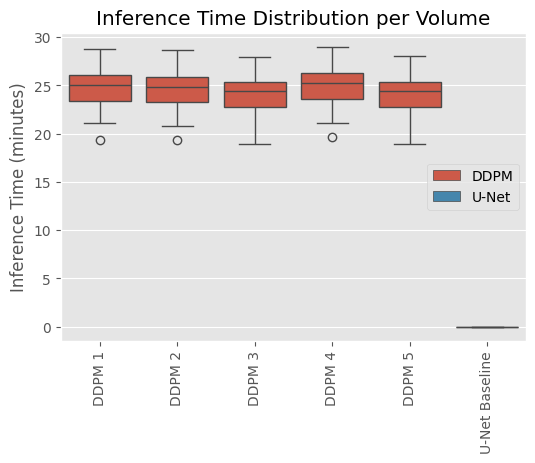

In [25]:
_ = comparison.plot_inference_times()

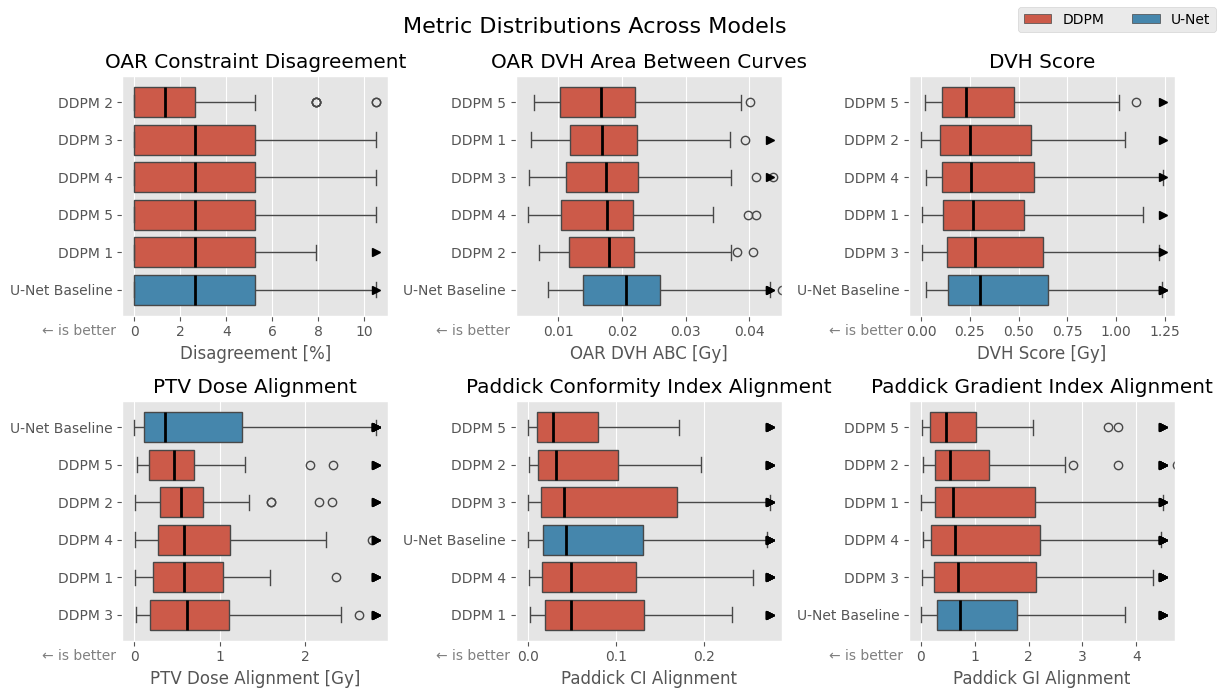

In [26]:
_ = comparison.plot_metric_distributions(METRICS_PRED, outliers=False, sort=True)

### General BeamDiff Uncertainty

In [27]:
all_results = [baseline1, baseline2, baseline3, baseline4, baseline5]

for seed in range(2, 11):
  all_results.append(ModelResults('112-beamdiff-bf16', f'ddpm-seed{seed}-1000', 199, 'test', dataset))
  all_results.append(ModelResults('136-beamdiff-bf16-2', f'ddpm-seed{seed}-1000', 199, 'test', dataset))
  all_results.append(ModelResults('137-beamdiff-bf16-3', f'ddpm-seed{seed}-1000', 199, 'test', dataset))
  all_results.append(ModelResults('138-beamdiff-bf16-4', f'ddpm-seed{seed}-1000', 199, 'test', dataset))
  all_results.append(ModelResults('139-beamdiff-bf16-5', f'ddpm-seed{seed}-1000', 199, 'test', dataset))

all_results_comparison = ModelComparison(all_results, ['Model 1'] * 10 + ['Model 2'] * 10 + ['Model 3'] * 10 + ['Model 4'] * 10 + ['Model 5'] * 10, ['DDPM'] * 50)

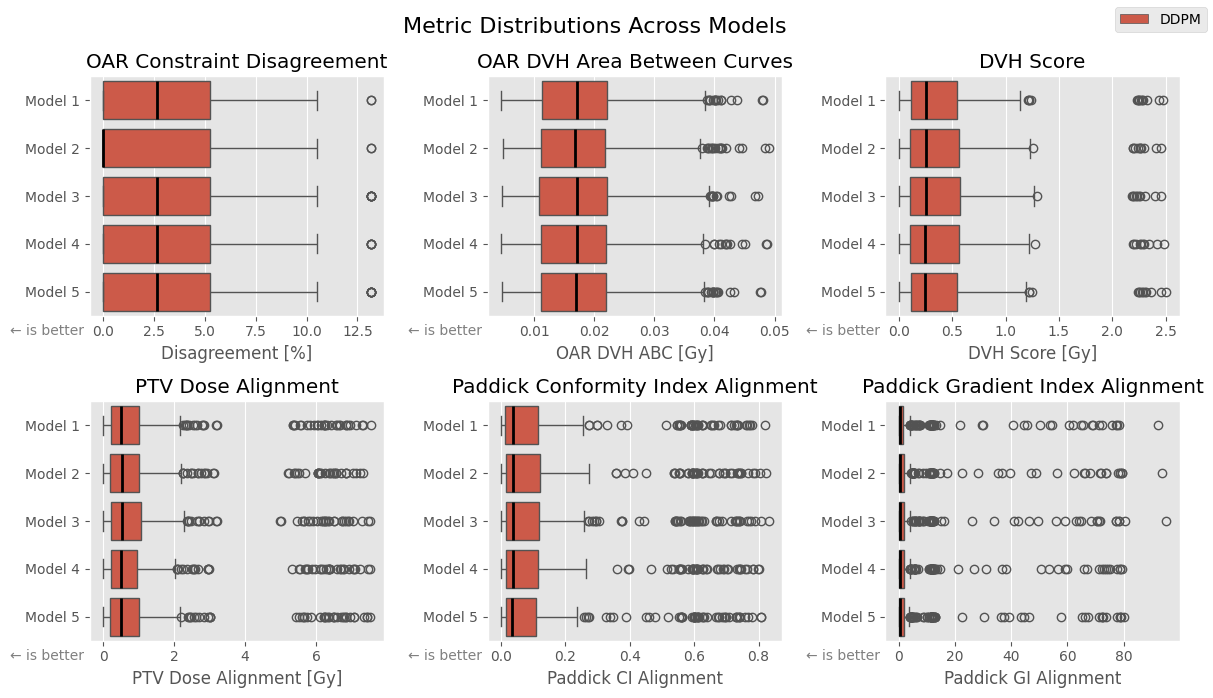

In [52]:
_ = all_results_comparison.plot_metric_distributions(METRICS_PRED, outliers=True, sort=False)

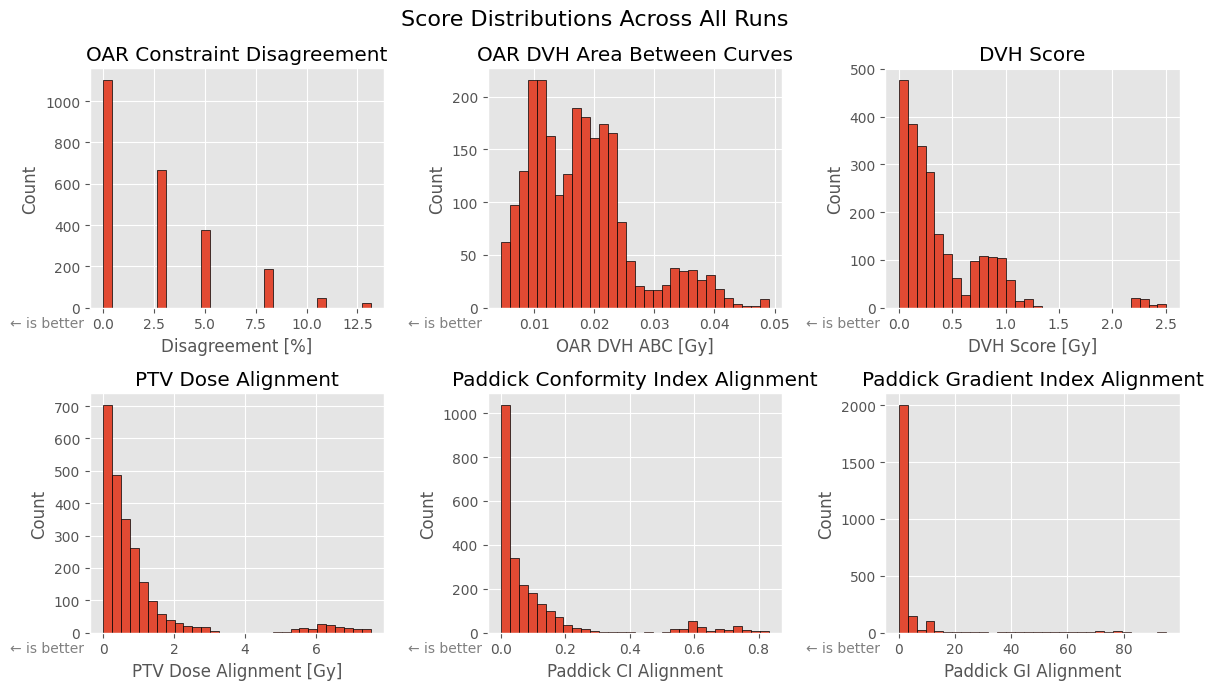

In [29]:
fig, axes = setup_fig_axes(METRICS_PRED)

for i, metric in enumerate(METRICS_PRED):
    values = []
    for result in all_results_comparison.results_list:
        if metric in result.volume_metrics.columns:
            values.extend(result.volume_metrics[metric].tolist())

    ax = axes[i]
    ax.hist(values, bins=30, edgecolor='black', linewidth=0.5)

    dir_symbol = '→' if is_higher_better(metric) else '←'
    ax.set_title(get_metric_label(metric))
    ax.set_xlabel(get_metric_abbr(metric))
    ax.set_ylabel('Count')
    ax.text(0.01, -0.035, f'{dir_symbol} is better  ', transform=ax.transAxes,
            ha='right', va='top', fontsize='medium', color='gray')

fig.suptitle('Score Distributions Across All Runs', fontsize=16)
fig.tight_layout()

### Per-Subject Variability Analysis

In [30]:
import numpy as np

# Build a long-form DataFrame with all runs pooled, keyed by subject
rows = []
for result in all_results_comparison.results_list:
    for _, row in result.volume_metrics.iterrows():
        rows.append(row)

all_volumes = pd.DataFrame(rows)

# Per-subject statistics for each metric
per_subject = {}
for metric in METRICS_PRED:
    grouped = all_volumes.groupby('file_name')[metric]
    per_subject[metric] = pd.DataFrame({
        'median': grouped.median(),
        'iqr': grouped.quantile(0.75) - grouped.quantile(0.25),
        'range': grouped.max() - grouped.min(),
        'q025': grouped.quantile(0.025),
        'q975': grouped.quantile(0.975),
    })

per_subject[METRICS_PRED[0]].head()

,median,iqr,range,q025,q975
file_name,,,,,
0522c0027+A4Ac+MOS_30413,0.000000,1.973686,2.631581,0.000000,2.631581
0522c0142+A4Ac+MOS_43691,0.000000,0.000000,0.000000,0.000000,0.000000
0522c0444+A4Ac+MOS_24107,5.263156,2.631575,5.263156,2.631581,7.894737
0522c0555+A4Ac+MOS_22329,0.000000,2.631581,2.631581,0.000000,2.631581
0522c0629+A4Ac+MOS_1367,2.631581,0.000000,0.000000,2.631581,2.631581


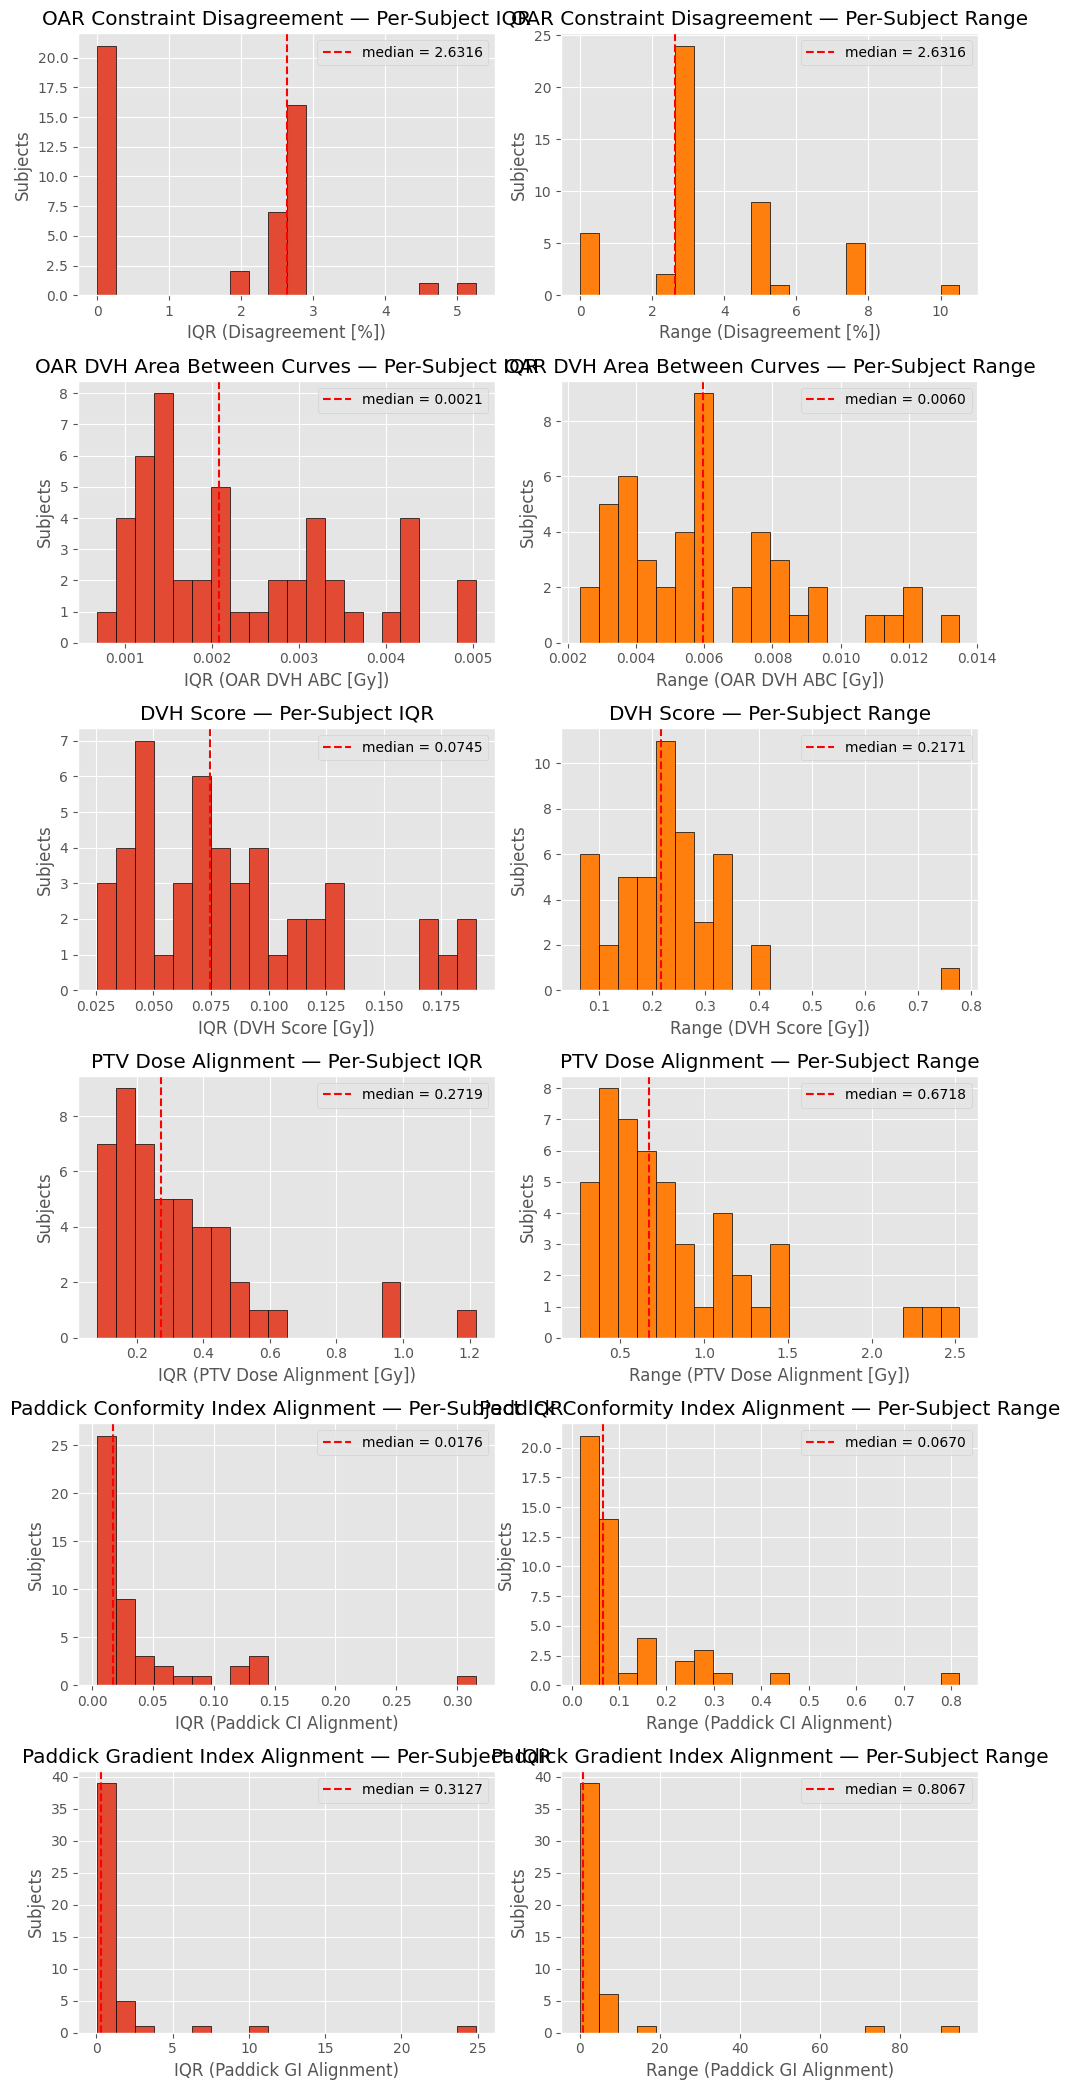

In [31]:
# 1) Per-subject IQR  &  2) Per-subject range — as histograms
fig, axes = plt.subplots(len(METRICS_PRED), 2, figsize=(10, 3.5 * len(METRICS_PRED)))

for i, metric in enumerate(METRICS_PRED):
    stats = per_subject[metric]
    label = get_metric_label(metric)
    abbr = get_metric_abbr(metric)

    # IQR histogram
    ax = axes[i, 0]
    ax.hist(stats['iqr'], bins=20, edgecolor='black', linewidth=0.5)
    median_iqr = stats['iqr'].median()
    ax.axvline(median_iqr, color='red', linestyle='--', label=f'median = {median_iqr:.4f}')
    ax.set_title(f'{label} — Per-Subject IQR')
    ax.set_xlabel(f'IQR ({abbr})')
    ax.set_ylabel('Subjects')
    ax.legend()

    # Range histogram
    ax = axes[i, 1]
    ax.hist(stats['range'], bins=20, edgecolor='black', linewidth=0.5, color='tab:orange')
    median_range = stats['range'].median()
    ax.axvline(median_range, color='red', linestyle='--', label=f'median = {median_range:.4f}')
    ax.set_title(f'{label} — Per-Subject Range')
    ax.set_xlabel(f'Range ({abbr})')
    ax.set_ylabel('Subjects')
    ax.legend()

fig.tight_layout()
plt.show()

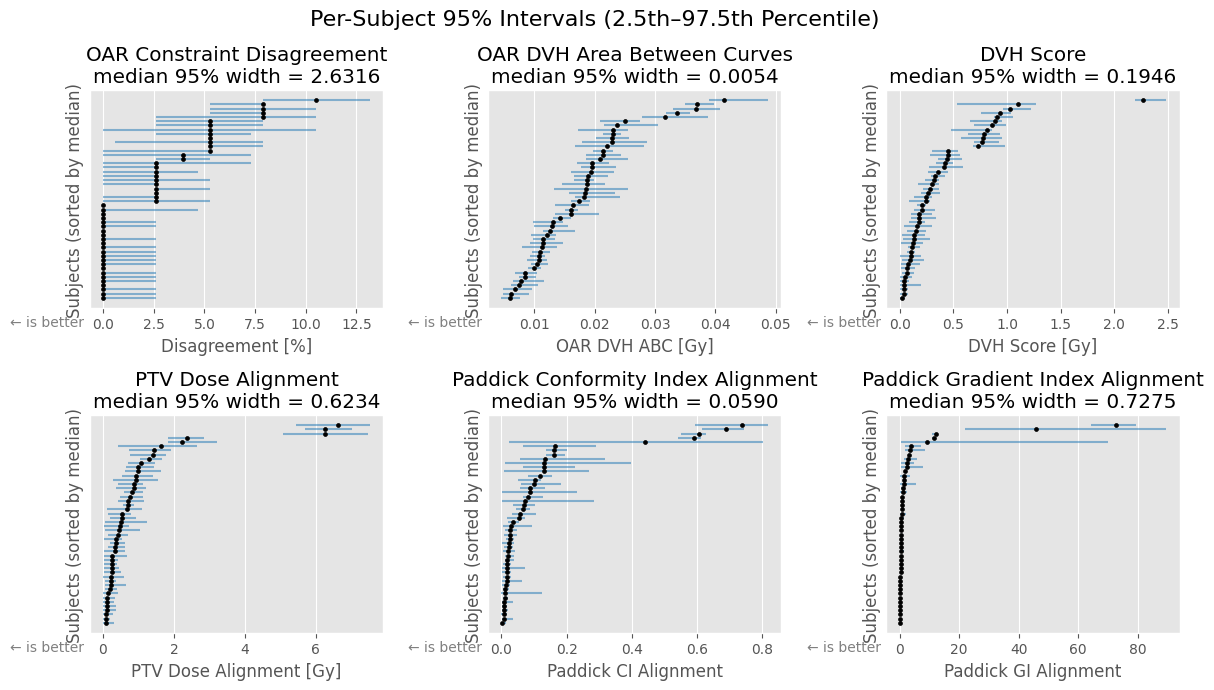

In [53]:
# 4) Per-subject 95% range (2.5th–97.5th percentile interval)
fig, axes = setup_fig_axes(METRICS_PRED)

for i, metric in enumerate(METRICS_PRED):
    stats = per_subject[metric].sort_values('median')
    label = get_metric_label(metric)
    abbr = get_metric_abbr(metric)
    ax = axes[i]

    # Plot each subject as a horizontal bar from q025 to q975, with median dot
    y = np.arange(len(stats))
    ax.hlines(y, stats['q025'], stats['q975'], color='tab:blue', alpha=0.5, linewidth=1.5)
    ax.scatter(stats['median'], y, color='black', s=8, zorder=3)

    # Median width of the 95% interval
    widths = stats['q975'] - stats['q025']
    median_width = widths.median()

    dir_symbol = '→' if is_higher_better(metric) else '←'
    ax.set_title(f'{label}\nmedian 95% width = {median_width:.4f}')
    ax.set_xlabel(abbr)
    ax.set_ylabel('Subjects (sorted by median)')
    ax.set_yticks([])
    ax.text(0.01, -0.035, f'{dir_symbol} is better  ', transform=ax.transAxes,
            ha='right', va='top', fontsize='medium', color='gray')

fig.suptitle('Per-Subject 95% Intervals (2.5th–97.5th Percentile)', fontsize=16)
fig.tight_layout()
plt.show()

In [33]:
# Summary table: median IQR, median range, and median 95% width per metric
summary_rows = []
for metric in METRICS_PRED:
    stats = per_subject[metric]
    widths = stats['q975'] - stats['q025']
    summary_rows.append({
        'Metric': get_metric_label(metric),
        'Median IQR': stats['iqr'].median(),
        'Median Range': stats['range'].median(),
        'Median 95% Width': widths.median(),
    })

summary_df = pd.DataFrame(summary_rows).set_index('Metric')
summary_df

,Median IQR,Median Range,Median 95% Width
Metric,,,
OAR Constraint Disagreement,2.631575,2.631581,2.631581
OAR DVH Area Between Curves,0.002079,0.005959,0.005353
DVH Score,0.074520,0.217114,0.194600
PTV Dose Alignment,0.271932,0.671795,0.623383
Paddick Conformity Index Alignment,0.017625,0.067011,0.059024
Paddick Gradient Index Alignment,0.312681,0.806653,0.727503


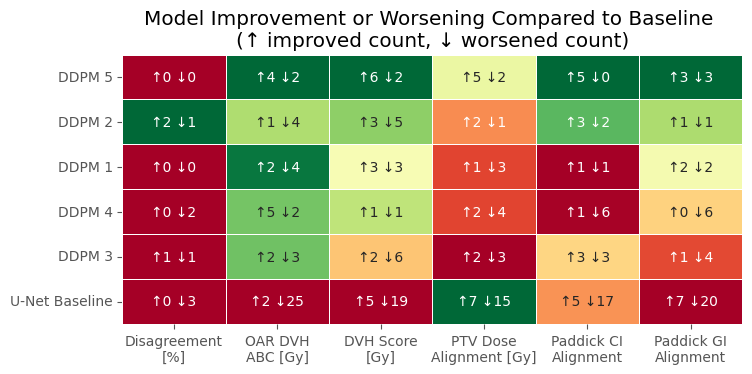

In [50]:
_ = comparison.plot_metric_heatmap(METRICS_PRED, baseline=all_results_comparison, improved_q=0.95, worsened_q=0.05)

## DeepLabv3+

In [10]:
deeplabv3plus_1 = ModelResults('147-deeplabv3plus-l2', 'unet', 199, 'test', dataset)
deeplabv3plus_2 = ModelResults('148-deeplabv3plus-2', 'unet', 199, 'test', dataset)
deeplabv3plus_3 = ModelResults('149-deeplabv3plus-3', 'unet', 199, 'test', dataset)
deeplabv3plus_4 = ModelResults('150-deeplabv3plus-4', 'unet', 199, 'test', dataset)
deeplabv3plus_5 = ModelResults('151-deeplabv3plus-5', 'unet', 199, 'test', dataset)

In [11]:
deeplabv3plus_comparison = ModelComparison(
  [deeplabv3plus_1, deeplabv3plus_2, deeplabv3plus_3, deeplabv3plus_4, deeplabv3plus_5, unet_baseline],
  ['Run 1', 'Run 2', 'Run 3', 'Run 4', 'Run 5', 'Baseline'],
  ['L2 Loss'] * 5 + ['L1 Loss']
)

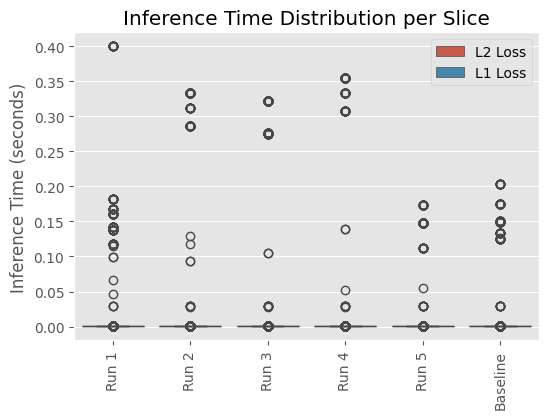

In [12]:
_ = deeplabv3plus_comparison.plot_inference_times('slice', 'seconds')

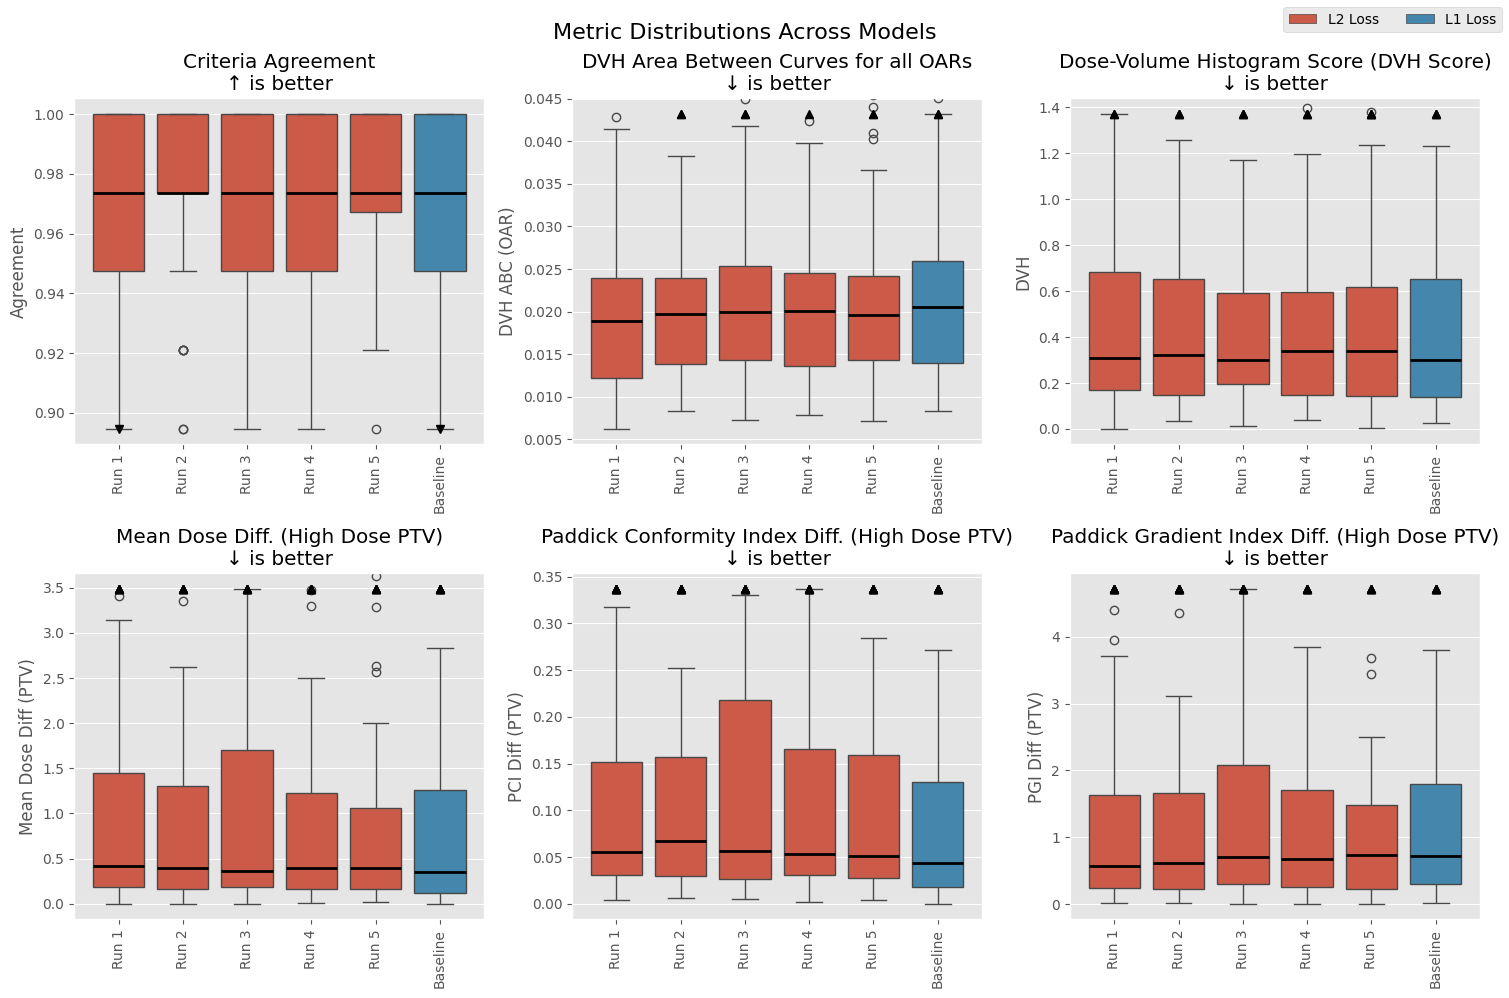

In [13]:
_ = deeplabv3plus_comparison.plot_metric_distributions(METRICS_PRED, outliers=False)

In [ ]:
_ = deeplabv3plus_comparison.plot_metric_heatmap(METRICS_PRED, baseline=all_results_comparison)